# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [4]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

## Read main path to .zarr file

In [8]:
path_data = "/media/sergio/Meninges/troutpy/raw/cosmx_mousebrain/GSE263791_RAW/sample1"
sdata = spatialdata_io.cosmx(path_data, dataset_id="GSM8199188_ID61-ID62_S10")

output_path = "/media/sergio/Meninges/troutpy/rois/cosmx_mousebrain"

INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to 

In [9]:
############ THIS CAN BE REMOVED; SINCE IT'S INCLUDED ON GIT ####################

import numpy as np
import pandas as pd
import copy
import spatialdata as sd
import xarray as xr
from spatialdata.models import Image2DModel, Labels2DModel, TableModel
from spatialdata.transformations import get_transformation
from spatialdata.transformations import Affine, Scale, Sequence, Translation, set_transformation


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches image tiles into a single global image.
    """
    fov_keys = list(sdata.images.data.keys())
    sample_raw = sdata.images.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, "compute") else sample_raw
    h, w = sample.shape[1:]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.images.data[key].transform["global"].matrix
        x_offs[key], y_offs[key] = M[0, 2], M[1, 2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))
    canvas = np.zeros((3, canvas_h, canvas_w), dtype=np.uint8)
    for key in fov_keys:
        tile_raw = sdata.images.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, "compute") else tile_raw
        x0 = int(round(x_offs[key] - x_min))
        y0 = int(round(y_offs[key] - y_min))
        canvas[:, y0 : y0 + h, x0 : x0 + w] = tile
    return xr.DataArray(canvas, dims=("c", "y", "x"))


def process_label_data(sdata: sd.SpatialData) -> (xr.DataArray, dict):
    """
    Stitches label tiles, assigns unique IDs, and returns mapping from (fov, original_cell_ID) to new unique ID.
    """
    fov_keys = list(sdata.labels.data.keys())
    sample_raw = sdata.labels.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, "compute") else sample_raw
    h, w = sample.shape[:2]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.labels.data[key].transform["global"].matrix
        x_offs[key], y_offs[key] = M[0, 2], M[1, 2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))
    global_lbl = np.zeros((canvas_h, canvas_w), dtype=sample.dtype)

    next_id = 1
    id_map = {}
    for key in fov_keys:
        # derive numeric fov from key, e.g. '1_points' -> 1
        fov = int(str(key).split("_", 1)[0])
        tile_raw = sdata.labels.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, "compute") else tile_raw
        unique_ids = np.unique(tile[tile > 0])
        # map using numeric fov
        tile_map = {(fov, orig): next_id + i for i, orig in enumerate(unique_ids)}
        id_map.update(tile_map)
        next_id += len(unique_ids)
        rel = np.zeros_like(tile)
        for (fv, orig), new in tile_map.items():
            rel[tile == orig] = new
        x0 = int(round(x_offs[key] - x_min))
        y0 = int(round(y_offs[key] - y_min))
        sub = global_lbl[y0 : y0 + h, x0 : x0 + w]
        mask = (sub == 0) & (rel > 0)
        sub[mask] = rel[mask]
        global_lbl[y0 : y0 + h, x0 : x0 + w] = sub
    return xr.DataArray(global_lbl, dims=("y", "x")), id_map


def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """
    Concatenates transcript tiles, keeps fov (numeric) for remapping.
    """
    dfs = []
    for key in sdata.points.data.keys():
        fov = int(str(key).split("_", 1)[0])
        elem = sdata.points.data[key]
        raw = elem.data if hasattr(elem, "data") else elem
        df = raw.compute() if hasattr(raw, "compute") else raw
        df["fov"] = fov
        dfs.append(df)
    tx = pd.concat(dfs, ignore_index=True)
    tx["local_x"] = tx["x"]
    tx["local_y"] = tx["y"]
    tx.drop(columns=["x", "y"], inplace=True)
    tx.rename(columns={"x_global_px": "x", "y_global_px": "y", "target": "gene"}, inplace=True)
    tx["transcript_id"] = np.arange(len(tx))
    tx["overlaps_cell"] = tx["cell_ID"] != 0
    tx["overlaps_nuclei"] = tx["CellComp"] == "Nuclear"
    tx["overlaps_nuclei"].fillna(False, inplace=True)
    tx["control_probe"] = tx["gene"].str.startswith("NegPrb")
    if "global" in sdata["table"].obsm:
        sdata["table"].obsm["spatial"] = sdata["table"].obsm["global"].copy()
    return tx


def cosmx_converter(sdata: sd.SpatialData, copy_data: bool = False) -> sd.SpatialData:
    """Main converter: stitches, remaps cell_IDs by (fov,orig)->global."""
    sdata_out = copy.deepcopy(sdata) if copy_data else sdata
    # 1) stitch
    img_da = process_image_data(sdata_out)
    lbl_da, id_map = process_label_data(sdata_out)
    # 2) transcripts
    tx_df = process_transcript_data(sdata_out)
    # 3) remap transcripts
    tx_df["cell_ID"] = tx_df.apply(lambda r: id_map.get((r["fov"], r["cell_ID"]), 0), axis=1).astype(int)
    # 4) remap table
    if "cell_ID" in sdata_out.table.obs:
        if "fov" not in sdata_out.table.obs.columns:
            raise ValueError("table.obs must contain numeric 'fov' column to remap cell_IDs.")
        sdata_out.table.obs["cell_ID"] = sdata_out.table.obs.apply(
            lambda r: id_map.get((int(r["fov"]), r["cell_ID"]), 0), axis=1
        ).astype(int)
    # 5) shift coords
    min_x, min_y = tx_df["x"].min(), tx_df["y"].min()
    tx_df["x"] -= min_x
    tx_df["y"] -= min_y
    if "spatial" in sdata_out.table.obsm:
        sdata_out.table.obsm["spatial"][:, 0] -= min_x
        sdata_out.table.obsm["spatial"][:, 1] -= min_y

    # modify coords from pixels to um
    cosmx_px_to_um = 0.12028
    tx_df["x"] = tx_df["x"] * cosmx_px_to_um
    tx_df["y"] = tx_df["y"] * cosmx_px_to_um
    sdata_out.table.obsm["spatial"][:, 0] = sdata_out.table.obsm["spatial"][:, 0] * cosmx_px_to_um
    sdata_out.table.obsm["spatial"][:, 1] = sdata_out.table.obsm["spatial"][:, 1] * cosmx_px_to_um

    # 6) pack
    sdata_out.images = {
        "morphology_focus": Image2DModel.parse(
            data=img_da, scale_factors=(2, 2), c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data
        )
    }
    sdata_out.labels = {"labels": Labels2DModel.parse(data=lbl_da, scale_factors=(2, 2))}
    sdata_out.points = {
        "transcripts": sd.models.PointsModel.parse(tx_df)
    }  # we should get this done eventually #transformations={'global': np.array([[1/cosmx_px_to_um, 0, 0],[0, 1/cosmx_px_to_um, 0],[0, 0,   1]])})}
    # 7) shapes + metadata
    sdata_out["shapes"] = sd.to_polygons(sdata_out.labels["labels"])
    sdata_out["shapes"].index = sdata_out["shapes"].index.astype(int)

    transform = Affine(
        [
            [cosmx_px_to_um, 0, 0],
            [0, cosmx_px_to_um, 0],
            [0, 0, 1],
        ],
        input_axes=("x", "y"),
        output_axes=("x", "y"),
    )

    set_transformation(sdata_out.shapes["shapes"], transform, to_coordinate_system="global")

    # format data

    sdata["table"].obs["region"] = "shapes"
    original_table = sdata["table"].copy()
    try:
        del original_table.uns["spatialdata_attrs"]
    except:
        pass
    # re-parse that AnnData into a SpatialData table layer
    sdata["table"] = TableModel.parse(
        original_table,
        region="shapes",  # or whatever region_key you want
        region_key="region",
        instance_key="cell_ID",
    )

    return sdata_out if copy_data else None

In [10]:
cosmx_converter(sdata)

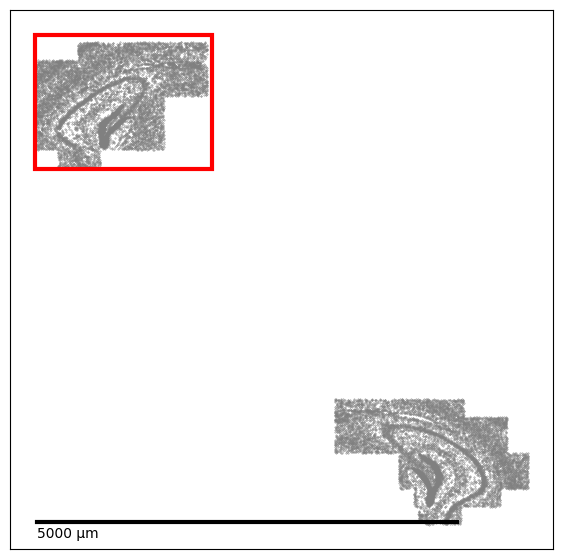

In [22]:
# ROI selection
bb_xmin = 0 * 0.12  # mix x
bb_ymin = 85000 * 0.12  # min y
bb_xmax = 17600 * 0.12  # max x
bb_ymax = 117000 * 0.12  # max y

plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"],
    bb_xmin=bb_xmin,
    bb_xmax=bb_xmax,
    bb_ymin=bb_ymin,
    bb_ymax=bb_ymax,
    pixel_size_um=1,
)

In [23]:
sdata["table"].obs["x"] = [s[0] for s in sdata["table"].obsm["spatial"]]
sdata["table"].obs["y"] = [s[1] for s in sdata["table"].obsm["spatial"]]

cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

In [27]:
# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="cosmx_mshippocampus",
    species="Mus musculus",
    technology="CosMx",
    segmentation_method="cosmx-default",
    roi_name="roi_ms_cortex_ad",
    tissue="Brain (hippocampus)",
    disease="Alzheimer's disease model",
)

rechunk_sdata(cropped_sdata)

Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
Processing label: labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...


In [26]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/rois/cosmx_mousebrain/data.zarr                                            


In [28]:
cropped_sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/cosmx_mousebrain/data.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (3, 3840, 2112), (3, 1920, 1056), (3, 960, 528)
├── Labels
│     └── 'labels': DataTree[yx] (3840, 2112), (1920, 1056), (960, 528)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (2D points)
├── Shapes
│     └── 'shapes': GeoDataFrame shape: (11291, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (11291, 960)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), labels (Labels), transcripts (Points), shapes (Shapes)